In [1]:
from langgraph.graph import StateGraph,START,MessagesState
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages.utils import trim_messages,count_tokens_approximately

In [2]:
load_dotenv()

True

In [3]:
model=ChatGroq(model="openai/gpt-oss-20b",temperature=0)

In [4]:
max_tokens=150

In [5]:
def call_model(state: MessagesState):
    messages=trim_messages(
        state["messages"],
        strategy="last",
        token_counter=count_tokens_approximately,
        max_tokens=max_tokens
    )

    print('current token ->',count_tokens_approximately(messages=messages))

    for message in messages:
        print(message.content)
        response=model.invoke(messages)
        return {"messages":[response]}

In [6]:
builder=StateGraph(MessagesState)
builder.add_node("call_model",call_model)
builder.add_edge(START,"call_model")

In [7]:
checkpointer=InMemorySaver()
graph=builder.compile(checkpointer=checkpointer)

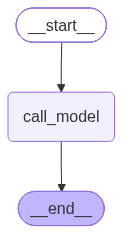

In [8]:
graph

In [9]:
config= {"configurable": {"thread_id":"chat-1"}}
result=graph.invoke({"messages":[{"role":"user","content":"hii! my name is nitish"}]},config)
result["messages"][-1].content

current token -> 10
hii! my name is nitish


'Hello Nitish! 👋 How can I help you today?'

In [10]:
result=graph.invoke({"messages":[{"role":"user","content":"I am learning langgraph"}]},config)
result["messages"][-1].content

current token -> 36
hii! my name is nitish


'That’s awesome! LangGraph is a powerful framework for building graph‑based language models and conversational agents. 🚀\n\n### Quick Overview\n| Topic | What it is | Why it matters |\n|-------|------------|----------------|\n| **Graph Nodes** | Individual “steps” (e.g., prompts, API calls, logic) | Keeps your workflow modular |\n| **Edges** | Connections that decide the next node | Enables dynamic branching |\n| **State** | Shared data passed between nodes | Keeps context consistent |\n| **Tools** | External APIs or functions you can call | Extends the model’s capabilities |\n| **LLM Integration** | The core language model driving decisions | Provides natural language understanding |\n\n---\n\n## Getting Started\n\n1. **Install LangGraph**  \n   ```bash\n   pip install langgraph\n   ```\n\n2. **Create a Simple Graph**  \n   ```python\n   from langgraph import Graph, State, Node\n\n   class GreetingNode(Node):\n       def run(self, state: State):\n           return {"message": "Hello, 

In [11]:
result=graph.invoke({"messages":[{"role":"user","content":"can you explain short term memory"}]},config)
result["messages"][-1].content

current token -> 13
can you explain short term memory


'### Short‑Term Memory (STM) – A Quick Overview\n\n| Feature | What it means |\n|---------|---------------|\n| **Capacity** | Roughly 7\u202f±\u202f2 “chunks” of information (Miller, 1956). A “chunk” can be a single digit, a word, or a meaningful group of items. |\n| **Duration** | About 15–30\u202fseconds without rehearsal; up to a minute with active rehearsal. |\n| **Function** | Holds information temporarily while it’s being processed, manipulated, or transferred to long‑term memory. |\n| **Structure** | Traditionally viewed as a single store, but modern models (e.g., Baddeley’s Working Memory) break it into subsystems: phonological loop, visuospatial sketchpad, central executive, and episodic buffer. |\n| **Encoding** | Primarily *verbal* (phonological) or *visual* (visuospatial). Rehearsal (repeating or mentally rehearsing) keeps items alive. |\n| **Decay vs. Interference** | Information fades over time (decay) and can be overwritten by new material (interference). |\n\n---\n\n## 

In [12]:
for item in graph.get_state({"configurable": {"thread_id":"chat-1"}}).values['messages']:
    print(item.content)
    print("_"*120)

hii! my name is nitish
________________________________________________________________________________________________________________________
Hello Nitish! 👋 How can I help you today?
________________________________________________________________________________________________________________________
I am learning langgraph
________________________________________________________________________________________________________________________
That’s awesome! LangGraph is a powerful framework for building graph‑based language models and conversational agents. 🚀

### Quick Overview
| Topic | What it is | Why it matters |
|-------|------------|----------------|
| **Graph Nodes** | Individual “steps” (e.g., prompts, API calls, logic) | Keeps your workflow modular |
| **Edges** | Connections that decide the next node | Enables dynamic branching |
| **State** | Shared data passed between nodes | Keeps context consistent |
| **Tools** | External APIs or functions you can call | Extends t